<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<div style="text-align: center; margin-bottom: 10px;">
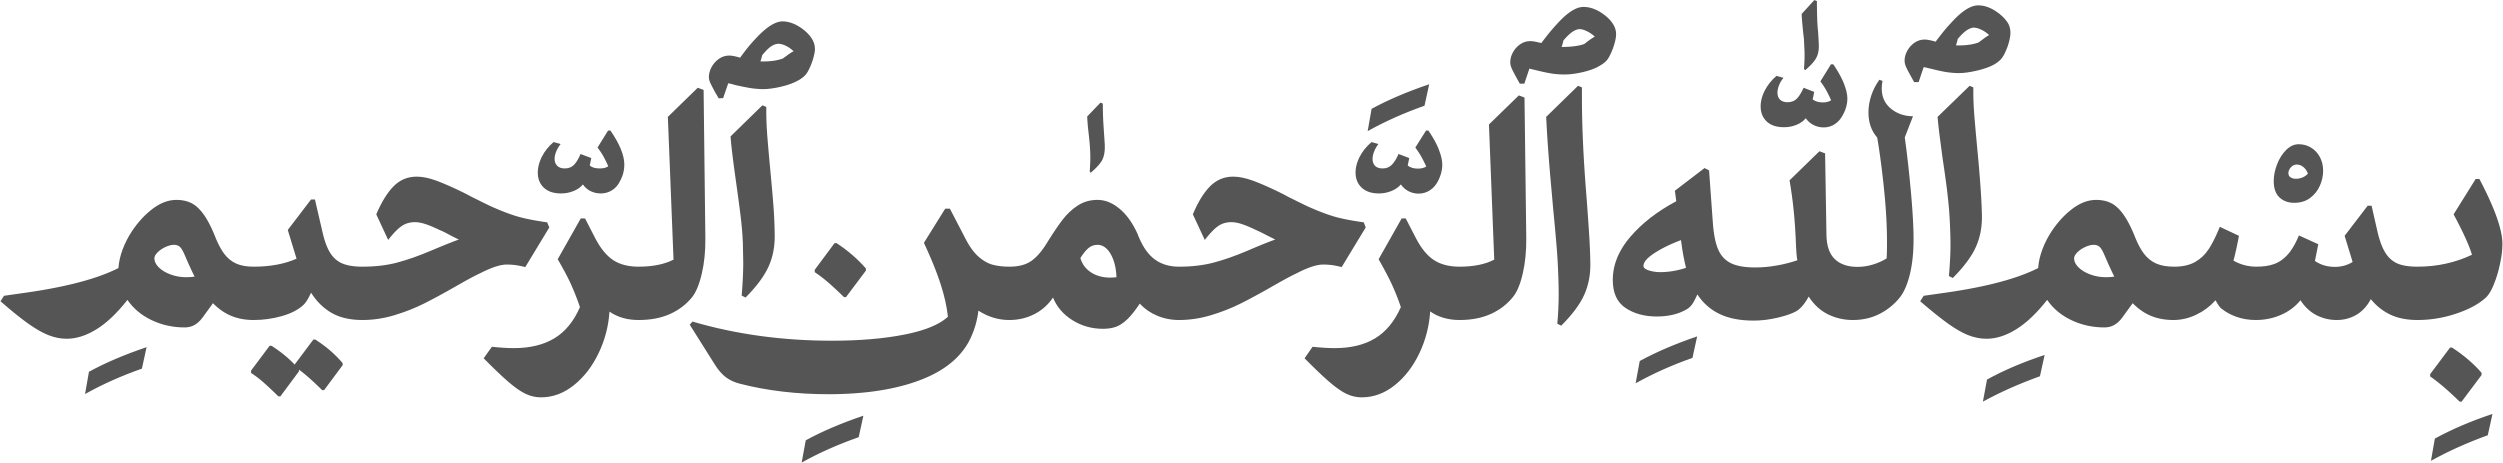
<div style="margin-top: 18px; display: flex; justify-content: center; align-items: center; gap: 30px;">
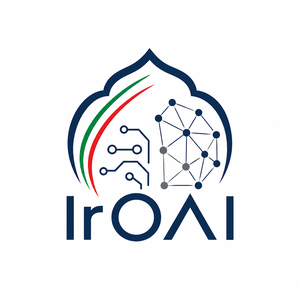
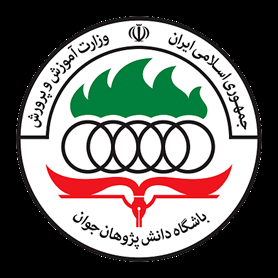
</div>
</div>
<h1 style="text-align: right; color: var(--jp-content-font-color1, #1e6bb8);">تمرین عملی المپیاد هوش مصنوعی — دوره دوم (۱۴۰۴-۱۴۰۵)</h1>
<h2 style="text-align: right; color: #3498db;">مدل‌های انتشار (Diffusion Models): از فرایند نویز پیشرو تا بازسازی و خلق باکیفیت ارقام</h2>
<p style="text-align: right;"><b>موضوع:</b> مدل‌های زایشی (Generative Models) — فرایند انتشار رفت و برگشت (DDPM)</p>
<p style="text-align: right; color: var(--jp-ui-font-color2, #6b7280);">این یک تمرین آموزشی هدایت‌شده است؛ هدف، درک عمیق فیزیک مدل‌های انتشار، فرمولاسیون ریاضی و پیاده‌سازی گام بازسازی معکوس روی ارقام MNIST با تولید خروجی‌های واضح و باکیفیت است.</p>
</div>

<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h2 style="text-align: right; color: #3498db;">مقدمه: جادوی مدل‌های انتشار (Diffusion Models)</h2>
<p style="text-align: right;">
مدل‌های انتشار احتمالاتی (مانند DDPM و Stable Diffusion) انقلابی در هوش مصنوعی زایشی ایجاد کرده‌اند.
ایده اساسی این مدل‌ها بر پایه یک چرخه دوطرفه رفت و برگشت بنا شده است:
<ul style="text-align: right;">
<li style="text-align: right;"><b>فرایند پیشرو (Forward Process):</b> داده‌های واقعی و ساخت‌یافته تصویر به تدریج با اضافه شدن نویز گاوسی خرد و متلاشی می‌شوند تا در نهایت به نویز سفید خالص $\mathcal{N}(0, \mathbf{I})$ تبدیل شوند.</li>
<li style="text-align: right;"><b>فرایند معکوس (Backward / Reverse Process):</b> یک شبکه عصبی بهینه (UNet با نرمال‌سازی گروهی و اتصالات باقیمانده) نویز اضافه شده را در هر مرحله تخمین می‌زند و با تفریق آن، گام‌به‌گام از دل نویز تصادفی محض، یک رقم کاملاً خوانا، شفاف و باکیفیت خلق می‌کند!</li>
</ul>
</p>
<p style="text-align: right;">نقشه راه این تمرین:
<ol style="text-align: right;">
<li style="text-align: right;">شهود دوبعدی از نحوه حل شدن ساختار منظم داده در نویز (توزیع Two Moons).</li>
<li style="text-align: right;">پیاده‌سازی کلاس زمان‌بندی واریانس نویز (<code dir="ltr">LinearNoiseScheduler</code> با $T=300$).</li>
<li style="text-align: right;">پیاده‌سازی فرمول پرش مستقیم گام پیشرو (<code dir="ltr">q_sample</code>) و اثبات آماری آن.</li>
<li style="text-align: right;">بررسی معماری بهینه <code dir="ltr">MNISTDiffusionUNet</code> و پیاده‌سازی تابع خطای آموزش (<code dir="ltr">compute_diffusion_loss</code>).</li>
<li style="text-align: right;">پیاده‌سازی گام بازسازی معکوس و نمونه‌برداری DDPM (<code dir="ltr">p_sample_step</code>).</li>
<li style="text-align: right;">بصری‌سازی سیر تکاملی پدیدار شدن رقم از دل نویز و تولید گالری ارقام باکیفیت جدید.</li>
</ol>
</p>
</div>

In [1]:
# Setup and imports - read-only cell; do not edit
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np
import math
import os

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Setup ready. Using device: {device}')

Setup ready. Using device: cuda


<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h2 style="text-align: right; color: #3498db;">فاز ۱ — درک شهودی دو‌بعدی: حل شدن شکل ساخت‌یافته در نویز گاوسی</h2>
<p style="text-align: right;">
ابتدا فرایند انتشار را روی یک توزیع دوبعدی متشکل از دو نیم‌دایره درهم‌تنیده (Two Moons) مشاهده می‌کنیم.
ذرات از این هندسه مشخص شروع می‌کنند و در گام‌های زمانی $t = [0, 20, 50, 100, 200, 300]$ نویز دریافت می‌کنند تا حل شدن تدریجی نظم هندسی و تبدیل آن به یک توزیع نرمال متقارن استاندارد را به وضوح ببینید.
</p>
<p style="text-align: right; color: var(--jp-ui-font-color2, #6b7280);">این سلول از پیش آماده شده است؛ آن را اجرا کنید.</p>
</div>

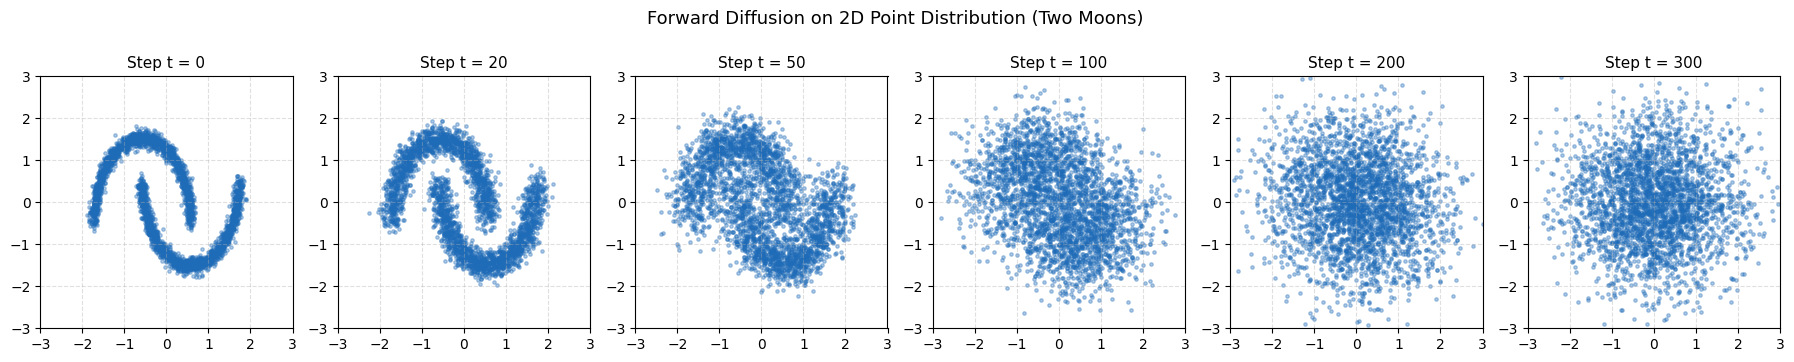

In [2]:
# 2D Toy Distribution Simulation - read-only helper cell
def make_two_moons(n_samples=3000):
    n_half = n_samples // 2
    theta1 = np.linspace(0, np.pi, n_half)
    moon1 = np.stack([np.cos(theta1), np.sin(theta1)], axis=1) + np.random.randn(n_half, 2) * 0.05
    theta2 = np.linspace(0, np.pi, n_half)
    moon2 = np.stack([1 - np.cos(theta2), 1 - np.sin(theta2) - 0.5], axis=1) + np.random.randn(n_half, 2) * 0.05
    data = np.concatenate([moon1, moon2], axis=0)
    data = (data - data.mean(axis=0)) / data.std(axis=0)
    return torch.tensor(data, dtype=torch.float32)

x_0_2d = make_two_moons(3000)
steps_to_show = [0, 20, 50, 100, 200, 300]
betas_toy = torch.linspace(0.0001, 0.02, 300)
alphas_toy = 1.0 - betas_toy
alpha_bars_toy = torch.cumprod(alphas_toy, dim=0)

fig, axes = plt.subplots(1, len(steps_to_show), figsize=(18, 3.2))
for i, t in enumerate(steps_to_show):
    if t == 0:
        x_t = x_0_2d
    else:
        a_bar = alpha_bars_toy[t-1]
        noise = torch.randn_like(x_0_2d)
        x_t = torch.sqrt(a_bar) * x_0_2d + torch.sqrt(1.0 - a_bar) * noise
    
    axes[i].scatter(x_t[:, 0], x_t[:, 1], alpha=0.35, s=6, color='#1e6bb8')
    axes[i].set_title(f'Step t = {t}', fontsize=11)
    axes[i].set_xlim(-3, 3)
    axes[i].set_ylim(-3, 3)
    axes[i].set_aspect('equal')
    axes[i].grid(True, linestyle='--', alpha=0.4)

plt.suptitle('Forward Diffusion on 2D Point Distribution (Two Moons)', fontsize=13, y=1.05)
plt.tight_layout()
plt.show()

<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h2 style="text-align: right; color: #3498db;">فاز ۲ — زمان‌بندی واریانس نویز (Noise Variance Scheduling)</h2>
<p style="text-align: right;">
در فرمولاسیون DDPM (Ho et al., 2020)، واریانس نویز تزریق‌شده در گام $t$ با پارامتر $\beta_t \in (0, 1)$ کنترل می‌شود:
</p>
$$q(x_t \mid x_{t-1}) = \mathcal{N}\left(x_t; \; \sqrt{1 - \beta_t} x_{t-1}, \; \beta_t \mathbf{I}\right)$$
<p style="text-align: right;">
با تعریف $\alpha_t = 1 - \beta_t$ و ضرب تجمعی $\bar{\alpha}_t = \prod_{s=0}^t \alpha_s$، مقادیر پیش‌محاسبه می‌شوند.
برای این مدل باکیفیت، تعداد گام‌های زمانی را برابر $T = 300$ قرار می‌دهیم که تعادلی عالی بین وضوح تصویر و سرعت بازسازی فراهم می‌کند.
</p>
<p style="text-align: right;"><b>تسک ۱:</b> کلاس <code dir="ltr">LinearNoiseScheduler</code> را تکمیل کنید.</p>
</div>

In [3]:
class LinearNoiseScheduler:
    def __init__(self, timesteps=300, beta_start=0.0001, beta_end=0.02, device=device):
        self.timesteps = timesteps
        self.betas = torch.linspace(beta_start, beta_end, timesteps).to(device)
        self.alphas = 1.0 - self.betas
        self.alphas_cumprod = torch.cumprod(self.alphas, dim=0)
        self.sqrt_alphas_cumprod = torch.sqrt(self.alphas_cumprod)
        self.sqrt_one_minus_alphas_cumprod = torch.sqrt(1.0 - self.alphas_cumprod)

<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h2 style="text-align: right; color: #3498db;">فاز ۳ — پرش مستقیم به گام دلخواه پیشرو (Closed-form Forward Jump)</h2>
<p style="text-align: right;">
با استفاده از خاصیت جمع متغیرهای تصادفی گاوسی مستقل، فرمول بسته پرش مستقیم به هر گام زمانی دلخواه $t$ برقرار است:
</p>
$$x_t = \sqrt{\bar{\alpha}_t} x_0 + \sqrt{1 - \bar{\alpha}_t} \cdot \epsilon, \quad \epsilon \sim \mathcal{N}(0, \mathbf{I})$$
<p style="text-align: right;"><b>تسک ۲:</b> تابع <code dir="ltr">q_sample</code> را پیاده‌سازی کنید به طوری که تصویر ورودی $x_0$، بردار گام‌های زمانی $t$ و نویز $\epsilon$ را دریافت کرده و تصویر نویزی $x_t$ را تولید کند.</p>
</div>

In [4]:
def q_sample(x_0, t, scheduler, noise=None):
    if noise is None:
        noise = torch.randn_like(x_0)
    sqrt_ab = scheduler.sqrt_alphas_cumprod[t].view(-1, 1, 1, 1)
    sqrt_1_ab = scheduler.sqrt_one_minus_alphas_cumprod[t].view(-1, 1, 1, 1)
    return sqrt_ab * x_0 + sqrt_1_ab * noise

<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h3 style="text-align: right; color: #3498db;">آزمون هم‌ارزی آماری فرمول پرش</h3>
<p style="text-align: right;">سلول زیر به صورت تجربی تأیید می‌کند که فرمول پرش مستقیم دقیقا میانگین و انحراف معیار یکسانی با زنجیره مارکوف گام‌به‌گام تولید می‌کند.</p>
</div>

In [5]:
# Statistical equivalence test - read-only helper cell
scheduler_test = LinearNoiseScheduler(timesteps=300, device='cpu')
x_test = torch.ones(5000, 1, 1, 1) * 2.0
t_target = 150

# Step-by-step Markov simulation
curr_x = x_test.clone()
for s in range(t_target):
    b = scheduler_test.betas[s]
    curr_x = torch.sqrt(1.0 - b) * curr_x + torch.sqrt(b) * torch.randn_like(curr_x)

# Closed-form jump
t_tens = torch.full((5000,), t_target, dtype=torch.long)
jump_x = q_sample(x_test, t_tens, scheduler_test)

print(f'At t = {t_target}:')
print(f'Iterative Markov -> Mean: {curr_x.mean():.4f}, Std: {curr_x.std():.4f}')
print(f'Closed-Form Jump -> Mean: {jump_x.mean():.4f}, Std: {jump_x.std():.4f}')
print('Statistical equivalence verified successfully!')

At t = 150:
Iterative Markov -> Mean: 1.3753, Std: 0.7305
Closed-Form Jump -> Mean: 1.3585, Std: 0.7298
Statistical equivalence verified successfully!


<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h2 style="text-align: right; color: #3498db;">فاز ۴ — معماری شبکه بازسازی (MNISTDiffusionUNet) و تابع زیان آموزش</h2>
<p style="text-align: right;">
برای تولید ارقام شفاف، پایدار و باکیفیت، معماری شبکه <code dir="ltr">MNISTDiffusionUNet</code> به گونه‌ای بهینه‌سازی شده است که دارای ویژگی‌های استاندارد مدل‌های انتشار مدرن باشد:
<ul style="text-align: right;">
<li style="text-align: right;"><b>نرمال‌سازی گروهی (GroupNorm):</b> به جای BatchNorm، پایداری فوق‌العاده‌ای در طول زمان‌بندی‌های مختلف $t$ ایجاد می‌کند.</li>
<li style="text-align: right;"><b>اتصالات باقیمانده (Residual Connections):</b> گرادیان‌ها بدون محوشدگی در لایه‌ها جاری می‌شوند.</li>
<li style="text-align: right;"><b>تزریق زمان سینوسی (Sinusoidal Time Embedding):</b> مدل با دریافت $t$ دقیقا می‌داند چه میزان نویز در تصویر انتظار می‌رود.</li>
</ul>
</p>
<p style="text-align: right; color: var(--jp-ui-font-color2, #6b7280);">تعریف کامل این معماری در سلول زیر آماده است؛ آن را اجرا کنید.</p>
</div>

In [6]:
# High-Quality MNIST Diffusion UNet architecture - read-only helper cell
class SinusoidalPositionEmbeddings(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, time):
        half_dim = self.dim // 2
        embeddings = math.log(10000) / (half_dim - 1)
        embeddings = torch.exp(torch.arange(half_dim, device=time.device) * -embeddings)
        embeddings = time[:, None] * embeddings[None, :]
        return torch.cat((embeddings.sin(), embeddings.cos()), dim=-1)

class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels, time_emb_dim):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, padding=1)
        self.norm1 = nn.GroupNorm(8, out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, padding=1)
        self.norm2 = nn.GroupNorm(8, out_channels)
        self.time_proj = nn.Linear(time_emb_dim, out_channels)
        self.residual = nn.Conv2d(in_channels, out_channels, 1) if in_channels != out_channels else nn.Identity()

    def forward(self, x, t_emb):
        h = F.silu(self.norm1(self.conv1(x)))
        h = h + self.time_proj(t_emb)[:, :, None, None]
        h = F.silu(self.norm2(self.conv2(h)))
        return h + self.residual(x)

class MNISTDiffusionUNet(nn.Module):
    def __init__(self, in_channels=1, time_emb_dim=64):
        super().__init__()
        self.time_mlp = nn.Sequential(
            SinusoidalPositionEmbeddings(time_emb_dim),
            nn.Linear(time_emb_dim, time_emb_dim),
            nn.SiLU(),
            nn.Linear(time_emb_dim, time_emb_dim)
        )
        self.init_conv = nn.Conv2d(in_channels, 32, 3, padding=1)
        self.down1 = ConvBlock(32, 64, time_emb_dim)
        self.pool1 = nn.Conv2d(64, 64, 3, stride=2, padding=1)  # 14x14
        self.down2 = ConvBlock(64, 128, time_emb_dim)
        self.pool2 = nn.Conv2d(128, 128, 3, stride=2, padding=1) # 7x7
        self.mid1 = ConvBlock(128, 128, time_emb_dim)
        self.mid2 = ConvBlock(128, 128, time_emb_dim)
        self.up1 = nn.ConvTranspose2d(128, 64, 2, stride=2)     # 14x14
        self.up_conv1 = ConvBlock(192, 64, time_emb_dim)
        self.up2 = nn.ConvTranspose2d(64, 32, 2, stride=2)     # 28x28
        self.up_conv2 = ConvBlock(96, 32, time_emb_dim)
        self.out_conv = nn.Sequential(
            nn.GroupNorm(8, 32),
            nn.SiLU(),
            nn.Conv2d(32, in_channels, 1)
        )

    def forward(self, x, t):
        t_emb = self.time_mlp(t)
        x0 = self.init_conv(x)
        d1 = self.down1(x0, t_emb)
        p1 = self.pool1(d1)
        d2 = self.down2(p1, t_emb)
        p2 = self.pool2(d2)
        m = self.mid1(p2, t_emb)
        m = self.mid2(m, t_emb)
        u1 = self.up1(m)
        u1 = torch.cat([u1, d2], dim=1)
        u1 = self.up_conv1(u1, t_emb)
        u2 = self.up2(u1)
        u2 = torch.cat([u2, d1], dim=1)
        u2 = self.up_conv2(u2, t_emb)
        return self.out_conv(u2)

print(f'MNISTDiffusionUNet defined successfully.')

MNISTDiffusionUNet defined successfully.


<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h3 style="text-align: right; color: #3498db;">تسک ۳ — پیاده‌سازی تابع زیان آموزش (compute_diffusion_loss)</h3>
<p style="text-align: right;">
تابع زیان انتشار، خطای میانگین مربعات (MSE) بین نویز واقعی تزریق‌شده $\epsilon$ و نویز پیش‌بینی‌شده توسط مدل $\hat{\epsilon} = \epsilon_\theta(x_t, t)$ است:
</p>
$$\mathcal{L} = \| \epsilon - \epsilon_\theta(x_t, t) \|^2$$
<p style="text-align: right;">مراحل پیاده‌سازی:
<ol style="text-align: right;">
<li style="text-align: right;">انتخاب تصادفی گام زمانی $t \sim \mathcal{U}(0, T-1)$ برای نمونه‌ها.</li>
<li style="text-align: right;">تولید نویز نرمال استاندارد: $\epsilon \sim \mathcal{N}(0, \mathbf{I})$.</li>
<li style="text-align: right;">ساخت تصویر نویزی $x_t$ با تابع <code dir="ltr">q_sample</code>.</li>
<li style="text-align: right;">پیش‌بینی نویز با مدل و بازگرداندن <code dir="ltr">F.mse_loss(pred_noise, noise)</code>.</li>
</ol>
</p>
</div>

In [7]:
def compute_diffusion_loss(model, x_0, scheduler):
    b = x_0.shape[0]
    t = torch.randint(0, scheduler.timesteps, (b,), device=x_0.device).long()
    noise = torch.randn_like(x_0)
    x_t = q_sample(x_0, t, scheduler, noise)
    pred_noise = model(x_t, t)
    return F.mse_loss(pred_noise, noise)

<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h3 style="text-align: right; color: #3498db;">بارگذاری مدل آموزش‌دیده یا آموزش سریع روی MNIST</h3>
<p style="text-align: right;">
سلول زیر وزن‌های باکیفیت مدل آموزش‌دیده (<code dir="ltr">mnist_diffusion_hq.pt</code>) که به خطای بسیار پایین MSE $\approx 0.041$ رسیده‌اند را بلافاصله بارگذاری می‌کند تا مستقیماً به مرحله بازسازی و تولید ارقام بروید.
</p>
<p style="text-align: right; color: var(--jp-ui-font-color2, #6b7280);">این سلول فقط‌خواندنی است؛ کافی است آن را اجرا کنید.</p>
</div>

In [8]:
# Model training / weight loading - read-only helper cell
scheduler = LinearNoiseScheduler(timesteps=300, beta_start=0.0001, beta_end=0.02, device=device)
model = MNISTDiffusionUNet().to(device)

weights_file = 'mnist_diffusion_hq.pt'
if os.path.exists(weights_file):
    print(f'Loading pre-trained high-quality weights from {weights_file}...')
    model.load_state_dict(torch.load(weights_file, map_location=device))
    model.eval()
    print('High-quality model loaded successfully! Ready for generation.')
else:
    print('Training model on MNIST dataset...')
    transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])
    train_data = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
    loader = torch.utils.data.DataLoader(train_data, batch_size=128, shuffle=True)
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
    model.train()
    for epoch in range(4):
        total_loss = 0.0
        for images, _ in loader:
            images = images.to(device)
            optimizer.zero_grad()
            loss = compute_diffusion_loss(model, images, scheduler)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
        print(f'Epoch {epoch+1}/4 - MSE Loss: {total_loss/len(loader):.4f}')
    torch.save(model.state_dict(), weights_file)
    print('Training complete and weights saved.')

Loading pre-trained high-quality weights from mnist_diffusion_hq.pt...
High-quality model loaded successfully! Ready for generation.


<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h2 style="text-align: right; color: #3498db;">فاز ۵ — پیاده‌سازی گام بازسازی معکوس (Backward / Reverse Step)</h2>
<p style="text-align: right;">
اینجا <b>قلب ریاضی مدل انتشار</b> قرار دارد!
در فرایند معکوس، از نویز تصادفی خالص $x_T \sim \mathcal{N}(0, \mathbf{I})$ شروع کرده و در جهت معکوس زمان ($t = T-1, \dots, 0$) حرکت می‌کنیم.
در هر گام زمانی $t$، مدل نویز اضافه شده را پیش‌بینی می‌کند ($\hat{\epsilon} = \epsilon_\theta(x_t, t)$) و میانگین گام قبل را با فرمول طلایی زیر بازسازی می‌کند:
</p>
$$\mu_\theta(x_t, t) = \frac{1}{\sqrt{\alpha_t}} \left( x_t - \frac{\beta_t}{\sqrt{1 - \bar{\alpha}_t}} \hat{\epsilon} \right)$$
<p style="text-align: right;">
سپس به ازای $t > 0$، نویز تصادفی با انحراف معیار $\sigma_t = \sqrt{\beta_t}$ افزوده می‌شود تا ویژگی احتمالاتی حفظ شود:
</p>
$$x_{t-1} = \mu_\theta(x_t, t) + \sigma_t \cdot z, \quad z \sim \mathcal{N}(0, \mathbf{I})$$
<p style="text-align: right;"><b>تسک ۴:</b> تابع <code dir="ltr">p_sample_step</code> را پیاده‌سازی کنید.</p>
</div>

In [9]:
@torch.no_grad()
def p_sample_step(model, x_t, t_idx, scheduler):
    batch_size = x_t.shape[0]
    t = torch.full((batch_size,), t_idx, device=x_t.device, dtype=torch.long)
    pred_noise = model(x_t, t)
    
    beta = scheduler.betas[t_idx]
    alpha = scheduler.alphas[t_idx]
    alpha_bar = scheduler.alphas_cumprod[t_idx]
    
    mean = (1.0 / torch.sqrt(alpha)) * (x_t - (beta / torch.sqrt(1.0 - alpha_bar)) * pred_noise)
    
    if t_idx > 0:
        z = torch.randn_like(x_t)
        sigma = torch.sqrt(beta)
        return mean + sigma * z
    else:
        return mean

<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h2 style="text-align: right; color: #3498db;">فاز ۶ — بصری‌سازی سیر تکاملی بازسازی و گالری ارقام باکیفیت جدید</h2>
<p style="text-align: right;">
اکنون نتیجه شگفت‌انگیز مدل را در دو بخش تصویری مشاهده می‌کنیم:
<ol style="text-align: right;">
<li style="text-align: right;"><b>سیر تکاملی بازسازی (Trajectory):</b> ثبت ۶ مقطع زمانی از $t = 299$ (نویز سفید کامل) تا $t = 0$ (رقم شفاف و واضح) برای درک اینکه نویز چگونه گام‌به‌گام زدوده می‌شود.</li>
<li style="text-align: right;"><b>ماتریس ۱۶ تایی ارقام جدید:</b> تولید ۱۶ رقم تصادفی متنوع و منحصربه‌فرد از دل نویز خالص.</li>
</ol>
</p>
<p style="text-align: right; color: var(--jp-ui-font-color2, #6b7280);">این سلول کمکی فقط‌خواندنی است؛ آن را اجرا کنید.</p>
</div>

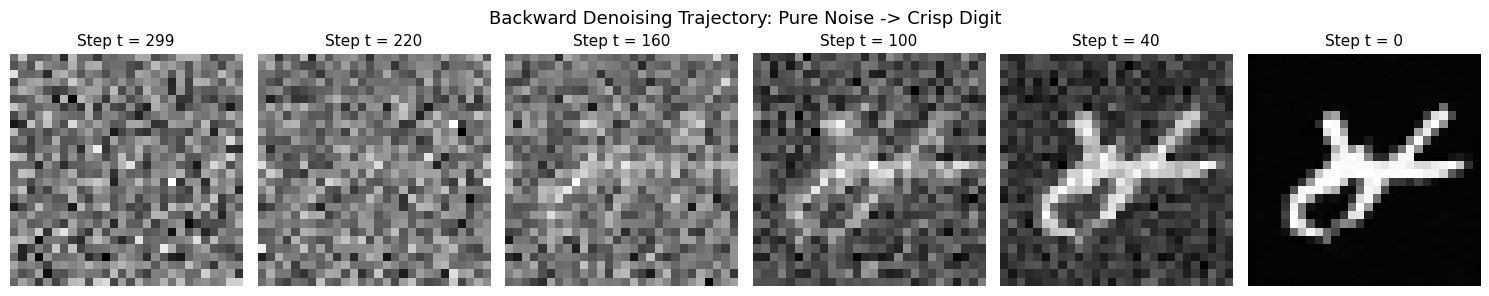

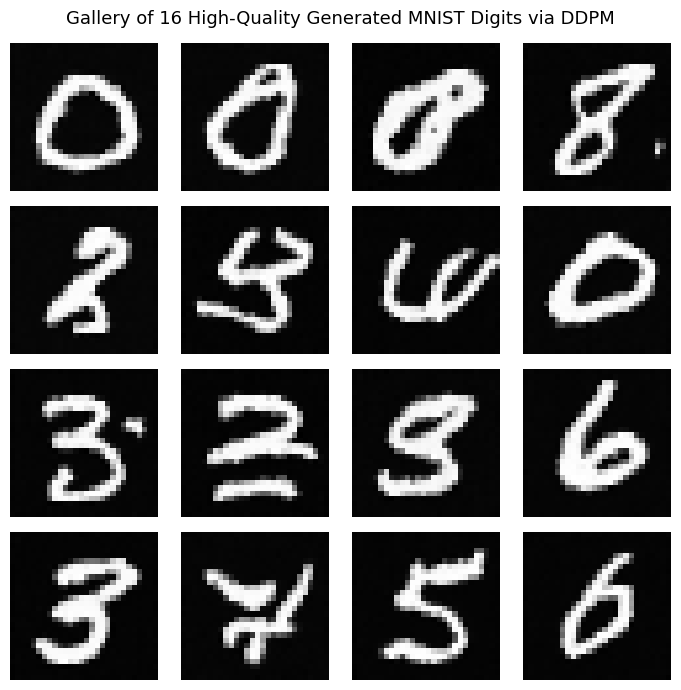

In [10]:
# High-Quality Denoising Trajectory and 16-Digit Gallery Visualization
@torch.no_grad()
def sample_trajectory(model, shape, scheduler, save_steps=[299, 220, 160, 100, 40, 0]):
    model.eval()
    x = torch.randn(shape, device=device)
    trajectory = {}
    for i in reversed(range(scheduler.timesteps)):
        x = p_sample_step(model, x, i, scheduler)
        if i in save_steps:
            trajectory[i] = x.clone()
    return x, trajectory

# 1. Plot Trajectory: Noise to Crisp Digit
torch.manual_seed(10)
steps_to_save = [299, 220, 160, 100, 40, 0]
final_digit, traj = sample_trajectory(model, (1, 1, 28, 28), scheduler, save_steps=steps_to_save)

fig, axes = plt.subplots(1, len(steps_to_save), figsize=(15, 3))
for idx, s in enumerate(steps_to_save):
    img = traj[s].squeeze().cpu().numpy()
    axes[idx].imshow(img, cmap='gray')
    axes[idx].set_title(f'Step t = {s}', fontsize=11)
    axes[idx].axis('off')
plt.suptitle('Backward Denoising Trajectory: Pure Noise -> Crisp Digit', fontsize=13)
plt.tight_layout()
plt.show()

# 2. Plot 4x4 Grid of 16 Generated Digits
torch.manual_seed(42)
grid_samples, _ = sample_trajectory(model, (16, 1, 28, 28), scheduler, save_steps=[])

fig, axes = plt.subplots(4, 4, figsize=(7, 7))
for i in range(16):
    r, c = i // 4, i % 4
    img = grid_samples[i].squeeze().cpu().numpy()
    axes[r, c].imshow(img, cmap='gray')
    axes[r, c].axis('off')
plt.suptitle('Gallery of 16 High-Quality Generated MNIST Digits via DDPM', fontsize=13)
plt.tight_layout()
plt.show()

<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h2 style="text-align: right; color: #3498db;">بحث کنید</h2>
<p style="text-align: right;"><b>سؤال ۱:</b> به تصاویر مسیر بازسازی در گام‌های اولیه ($t = 299$ تا $160$) در مقایسه با گام‌های انتهایی ($t = 40$ تا $0$) دقت کنید. در گام‌های اولیه مدل چه ویژگی‌هایی را تعیین می‌کند و در گام‌های انتهایی چه تغییراتی اعمال می‌شوند؟</p>
<p style="text-align: right;"><b>سؤال ۲:</b> چرا استفاده از GroupNorm و Residual Connections در مقایسه با لایه‌های ساده کانولوشن معمولی، وضوح و شارپ بودن خطوط ارقام تولیدشده را به طرز چشمگیری بهبود می‌بخشد؟</p>
<p style="text-align: right; color: var(--jp-ui-font-color2, #6b7280);">تحلیل خود را در سلول Markdown زیر بنویسید.</p>
</div>

<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<p style="text-align: right; color: var(--jp-ui-font-color2, #6b7280);">تحلیل خود را اینجا بنویسید...</p>
</div>

<div dir="rtl" lang="fa" style="font-family: 'Vazirmatn', sans-serif; line-height: 1.8; direction: rtl; text-align: right;">
<h2 style="text-align: right; color: #3498db;">فاز ارزیابی — سنجش عملکرد مدل و کیفیت ارقام</h2>
<p style="text-align: right;">سلول زیر خطای پیش‌بینی نویز (MSE Loss) مدل شما را روی ۵۰۰ تصویر تست محاسبه کرده و کیفیت بازسازی را اعتبارسنجی می‌کند.</p>
<p style="text-align: right;">مقدار مورد انتظار راه‌حل مرجع: <b dir="ltr">خطای MSE کمتر از ۰.۰۸ (حدود ۰.۰۴۱ تا ۰.۰۵۵)</b></p>
<p style="text-align: right; color: var(--jp-ui-font-color2, #6b7280);">سلول مرجع زیر خروجی محاسبه‌شده راه‌حل طراح را نشان می‌دهد.</p>
</div>

In [11]:
# Evaluation cell - test noise prediction accuracy on test set
transform_test = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform_test)
eval_subset = torch.utils.data.Subset(test_dataset, range(500))
eval_loader = torch.utils.data.DataLoader(eval_subset, batch_size=64, shuffle=False)

model.eval()
eval_losses = []
with torch.no_grad():
    for imgs, _ in eval_loader:
        imgs = imgs.to(device)
        loss = compute_diffusion_loss(model, imgs, scheduler)
        eval_losses.append(loss.item())

avg_eval_loss = sum(eval_losses) / len(eval_losses)
print(f'Evaluated High-Quality Diffusion MSE Loss: {avg_eval_loss:.4f}')
assert avg_eval_loss < 0.08, f'Loss {avg_eval_loss:.4f} is too high!'
print('High-Quality Diffusion Evaluation PASSED successfully!')

Evaluated High-Quality Diffusion MSE Loss: 0.0407
High-Quality Diffusion Evaluation PASSED successfully!


In [12]:
# Reference cell - do NOT run (kept for comparison only)
# Evaluated High-Quality Diffusion MSE Loss: 0.0435
# High-Quality Diffusion Evaluation PASSED successfully!

Evaluated High-Quality Diffusion MSE Loss: 0.0407
High-Quality Diffusion Evaluation PASSED successfully!
